# Prática 2 · Da foto ao JSON: a primeira chamada multimodal via API

**Desenvolvimento de Aplicações Interativas com LLMs Multimodais · Encontro 1 · PUC Minas**
Professor: Maurício Rodrigues da Silva

**Tempo:** 30 minutos · **Ambiente:** Google Colab · **Precisa de uma chave de API gratuita** (Groq ou Gemini)

### Objetivo
Enviar a foto de um cupom ou nota fiscal para um LLM com visão, receber os campos em JSON, **validar** cada campo contra o documento real e medir quantos tokens a imagem consome.

### Entrega
- Seu nome na célula de identificação.
- O JSON gerado, a validação campo a campo e a comparação de tokens, com as células executadas.
- O quiz do final respondido.

## Identificação

Preencha seu nome na célula abaixo e rode a célula antes de começar. Ele aparece no resumo do quiz, no final do notebook.

In [1]:
ALUNO = "Tales Rodrigo Ferreira Kerschner"        # seu nome completo, entre as aspas
MATRICULA = ""    # sua matrícula (opcional)

print("Aluno:", ALUNO or "(preencha o nome acima)")

Aluno: Tales Rodrigo Ferreira Kerschner


## 1. Conceitos que vamos usar

**API.** A forma de usar o modelo por código: enviamos uma requisição pela internet e recebemos a resposta.

**Chave de API.** Funciona como uma senha da sua conta. Nunca deve aparecer no código, em prints ou no GitHub.

**Compatibilidade com o SDK da OpenAI.** Vários provedores aceitam o mesmo formato de requisição criado pela OpenAI. Por isso, o mesmo código funciona com Groq, Gemini e OpenAI, trocando só o endereço (`base_url`), o modelo e a chave. Essa independência de fornecedor é um dos critérios de escolha de modelos vistos na aula.

**Limites de uso (rate limits).** Os provedores limitam requisições e tokens por minuto e por dia. Ao passar do limite, a API responde com o erro **429** e, em geral, informa quanto tempo esperar.

**Base64.** Uma forma de escrever a imagem como texto, para que ela viaje dentro da requisição.

**Mensagem multimodal.** O conteúdo da mensagem é uma lista com itens de tipos diferentes: texto e imagem lado a lado.

**Modo JSON.** Pede ao modelo uma resposta em JSON válido, que o código lê diretamente.

**Tokens.** A unidade em que o uso é medido e cobrado: texto e imagem são convertidos em tokens. O campo `usage` da resposta informa quantos foram usados.

**Acurácia por campo.** A fração de campos extraídos corretamente. É a métrica mais simples para avaliar extração de documentos.

### 1.1 Como um LLM com visão lê uma imagem

```
foto ──► encoder de visão ──► vetores dos patches ──► projetor ──► "tokens visuais" ─┐
                                                                                     ├──► LLM ──► texto, token a token
prompt ──► tokenizador ──────────────────────────────────────────► tokens de texto ──┘
```

1. O **encoder de visão**, um Transformer de imagem como o do CLIP da Prática 1, corta a foto em patches e transforma cada um em um vetor.
2. Um **projetor** (em geral, uma pequena rede neural) converte esses vetores para o mesmo espaço dos tokens de texto do LLM. Do ponto de vista do LLM, a imagem vira uma sequência de "palavras" a mais.
3. O **LLM** lê a sequência mista, tokens visuais e tokens do prompt, e gera a resposta um token por vez, sempre prevendo o próximo.

Duas consequências práticas para esta aula:
- **A imagem custa tokens.** Quanto mais patches, mais tokens de entrada. É por isso que a resolução afeta o custo e o limite por minuto (seção 5).
- **O modelo gera o texto mais provável, não necessariamente o verdadeiro.** Se o valor do cupom estiver borrado, o modelo ainda pode escrever um número plausível. Isso é uma **alucinação**, e é por isso que validamos cada campo (seção 4).

### 1.2 Anatomia de uma chamada de API

O pedido que o código envia tem este formato (a imagem foi encurtada):

```json
{
  "model": "nome-do-modelo-com-visao",
  "max_tokens": 400,
  "response_format": {"type": "json_object"},
  "messages": [
    {"role": "user",
     "content": [
       {"type": "text", "text": "Extraia do documento os campos emitente, data e valor_total..."},
       {"type": "image_url", "image_url": {"url": "data:image/jpeg;base64,/9j/4AAQSkZJRg..."}}
     ]}
  ]
}
```

| Campo | Para que serve |
| --- | --- |
| `model` | Qual modelo vai responder. Cada provedor tem os seus nomes. |
| `max_tokens` | Limite de tamanho da **resposta**. Evita respostas longas e gasto desnecessário. |
| `response_format` | Pede JSON válido. Nem todo provedor aceita; o código trata isso. |
| `messages` | A conversa. Cada mensagem tem um papel: `system` (instruções gerais), `user` (o usuário) ou `assistant` (respostas anteriores do modelo). |
| `content` | Pode ser um texto simples ou, numa mensagem multimodal, uma **lista** de itens de texto e de imagem. |

A resposta volta assim:

```json
{
  "choices": [{"message": {"role": "assistant", "content": "{\"emitente\": \"Lanchonete X\", ...}"}}],
  "usage": {"prompt_tokens": 1180, "completion_tokens": 38}
}
```

O texto gerado está em `choices[0].message.content` e a contagem de tokens em `usage`. O valor de `prompt_tokens` inclui os tokens do texto **e** os da imagem.

### 1.3 Por que validar e como medir

Em extração de documentos há dois tipos de erro:
- **Campo vazio (`null`):** o sistema admite que não sabe. Alguém preenche à mão; é chato, mas seguro.
- **Campo inventado:** um valor plausível e errado. Passa despercebido e vai parar na contabilidade. É o erro mais grave.

A métrica desta prática é a **acurácia por campo**:

$$\text{acurácia por campo} = \frac{\text{campos extraídos corretamente}}{\text{total de campos verificados}}$$

Com 1 documento e 3 campos, cada campo vale 33%. Com 3 documentos, você teria 9 campos e poderá calcular a acurácia **de cada campo** separadamente (por exemplo, a data acertou 3 de 3 e o emitente 1 de 3). Antes de comparar, os valores passam por uma **normalização** (minúsculas, sem espaços, sem "R$"), para que diferenças de formatação não contem como erro.

## Configuração: crie sua chave e cadastre no Colab

Este notebook funciona com três provedores, todos pelo mesmo SDK da OpenAI. Muda só o endereço da API, o nome do modelo e a chave. **Você precisa de pelo menos uma chave; o recomendado é ter duas (Groq e Gemini).**

| Provedor | Custo | Onde criar a chave | Nome do segredo no Colab (exatamente assim) | A chave começa com |
| --- | --- | --- | --- | --- |
| **Groq** (padrão) | Plano gratuito, sem cartão | console.groq.com/keys | `GROQ_API_KEY` | `gsk_` |
| **Gemini** (Google) | Plano gratuito, sem cartão | aistudio.google.com/apikey | `GEMINI_API_KEY` | `AIza` |
| **OpenAI** (opcional) | Pago, exige cartão | platform.openai.com/api-keys | `OPENAI_API_KEY` | `sk-` |

### Passo 1: criar a chave no site do provedor

**Groq**
1. Acesse console.groq.com e entre com sua conta Google ou GitHub (ou crie uma conta com e-mail).
2. No menu, abra **API Keys** e clique em **Create API Key**.
3. Dê um nome para a chave, por exemplo `puc-llm`, e confirme.
4. **Copie a chave na hora.** Ela aparece uma única vez; se perder, basta criar outra.

**Gemini**
1. Acesse aistudio.google.com e entre com sua conta Google.
2. Clique em **Get API key** e depois em **Create API key** (se pedir, escolha criar em um projeto novo).
3. Copie a chave.

### Passo 2: cadastrar a chave nos Secrets do Colab

1. Neste notebook, clique no **ícone de chave** 🔑 na barra lateral esquerda. Abre o painel **Secrets**.
2. Clique em **Adicionar novo secret** (*Add new secret*).
3. No campo **Nome** (*Name*), digite o nome da tabela acima, **exatamente igual**, em maiúsculas: `GROQ_API_KEY` para a chave do Groq, `GEMINI_API_KEY` para a do Gemini.
4. No campo **Valor** (*Value*), cole a chave, sem espaços nem aspas.
5. Ligue a chave **Acesso ao notebook** (*Notebook access*) na linha do segredo. Sem isso, o código não consegue ler a chave.
6. Repita para a segunda chave, se tiver.

Os segredos ficam guardados na sua conta Google e aparecem em todos os seus notebooks, mas o **acesso ao notebook precisa ser ligado em cada notebook novo** (na Prática 3, ligue de novo).

### Passo 3: conferir

Rode a célula abaixo. Ela mostra quais chaves o notebook encontrou, **sem exibir a chave**.

**Fora do Colab** (VS Code, Jupyter local): crie um arquivo `.env` na pasta do projeto com as linhas `GROQ_API_KEY=sua_chave` e `GEMINI_API_KEY=sua_chave`, e coloque `.env` no `.gitignore` para a chave nunca ir para o GitHub.

**Regras de segurança**
- A chave **nunca** é escrita no código, em uma célula ou em um print. Quem tiver sua chave usa sua cota.
- **Cada aluno usa a própria chave.** Os limites do plano gratuito valem por conta; uma chave dividida pela turma atinge o limite em minutos.
- Vazou a chave (por exemplo, num print ou no GitHub)? Apague-a no site do provedor e crie outra.

**Por que ter duas chaves:** os planos gratuitos têm limites de requisições e de tokens por minuto e por dia. Com Groq e Gemini cadastrados, o código troca de provedor sozinho quando um deles atingir o limite.

In [2]:
# Confere quais chaves o notebook consegue ler, sem mostrar o valor delas
import os
NOMES = ["GROQ_API_KEY", "GEMINI_API_KEY", "OPENAI_API_KEY"]
try:
    from google.colab import userdata
    for nome in NOMES:
        try:
            valor = userdata.get(nome)
            status = "OK, cadastrada e com acesso liberado" if valor else "existe, mas está vazia"
        except Exception as erro:
            tipo = type(erro).__name__
            if "Access" in tipo:
                status = "existe, mas o 'Acesso ao notebook' está desligado: ligue no painel Secrets"
            elif "NotFound" in tipo:
                status = "não cadastrada"
            else:
                status = f"não foi possível ler ({tipo})"
        print(f"{nome:16s} {status}")
except ImportError:
    from dotenv import load_dotenv
    load_dotenv()
    for nome in NOMES:
        print(f"{nome:16s} {'OK, encontrada no .env' if os.getenv(nome) else 'não encontrada no .env'}")
print("\nVocê precisa de pelo menos uma chave OK. A OpenAI é opcional.")

GROQ_API_KEY     OK, cadastrada e com acesso liberado
GEMINI_API_KEY   não cadastrada
OPENAI_API_KEY   não cadastrada

Você precisa de pelo menos uma chave OK. A OpenAI é opcional.


In [3]:
import os

PROVEDOR = "groq"   # troque para "gemini" ou "openai"

PROVEDORES = {
    "groq": {"base_url": "https://api.groq.com/openai/v1", "segredo": "GROQ_API_KEY",
             "modelo": "qwen/qwen3.8-27b"},
    "gemini": {"base_url": "https://generativelanguage.googleapis.com/v1beta/openai/", "segredo": "GEMINI_API_KEY",
               "modelo": "gemini-3.8-flash"},
    "openai": {"base_url": None, "segredo": "OPENAI_API_KEY",
               "modelo": "gpt-4o-mini"},
}
# Os nomes de modelos mudam com frequência. Se der erro de "model not found",
# confira um modelo com visão na documentação do provedor e atualize a linha acima.


def ler_segredo(nome):
    """Lê a chave dos Secrets do Colab ou do arquivo .env, sem nunca mostrá-la."""
    try:
        from google.colab import userdata
        try:
            return userdata.get(nome)
        except Exception:
            return None
    except ImportError:
        from dotenv import load_dotenv
        load_dotenv()
        return os.getenv(nome)


from openai import OpenAI

clientes = {}
for nome, cfg in PROVEDORES.items():
    chave = ler_segredo(cfg["segredo"])
    if chave:
        clientes[nome] = OpenAI(api_key=chave, base_url=cfg["base_url"])

if PROVEDOR not in clientes:
    raise RuntimeError(f"Cadastre o segredo {PROVEDORES[PROVEDOR]['segredo']} no Colab "
                       f"ou troque PROVEDOR para um destes: {list(clientes) or 'nenhum cadastrado'}")

ORDEM = [PROVEDOR] + [p for p in clientes if p != PROVEDOR]   # reservas, se houver
print("Provedor principal:", PROVEDOR, "| modelo:", PROVEDORES[PROVEDOR]["modelo"])
print("Reservas disponíveis:", ORDEM[1:] or "nenhuma (cadastre outra chave para ter reserva)")

Provedor principal: groq | modelo: qwen/qwen3.8-27b
Reservas disponíveis: nenhuma (cadastre outra chave para ter reserva)


**O que a célula de configuração faz**

1. `PROVEDOR` escolhe o provedor principal. `PROVEDORES` é um dicionário com, para cada provedor, o endereço da API (`base_url`), o nome do segredo onde está a chave e o modelo com visão que vamos usar.
2. `ler_segredo(nome)` tenta ler a chave dos Secrets do Colab. Fora do Colab, a importação de `google.colab` falha (`ImportError`) e a função lê o arquivo `.env`. Em nenhum caso a chave é impressa.
3. Para cada provedor com chave cadastrada, cria um cliente `OpenAI(api_key=..., base_url=...)`. É a **mesma classe** para os três provedores; só muda o endereço. Quando `base_url` é `None`, o cliente usa o endereço padrão da OpenAI.
4. `ORDEM` é a fila de tentativas: o provedor principal primeiro e, depois, os outros que tiverem chave. A função de chamada percorre essa fila quando um provedor falha.
5. Se o provedor principal não tiver chave, a célula para com uma mensagem dizendo qual segredo cadastrar.

### A função que faz as chamadas

Em vez de chamar a API diretamente, usamos a função `chamar_modelo`, que concentra três proteções importantes em aplicações reais:

- **Retentativa com espera exponencial (backoff):** se o provedor responder com o erro 429 (limite de uso atingido), a função espera e tenta de novo, dobrando a espera a cada tentativa. Quando o provedor informa quanto tempo esperar (cabeçalho `retry-after`), ela respeita esse valor.
- **Troca de provedor:** se as tentativas se esgotarem, ela passa para o próximo provedor com chave cadastrada.
- **Cache:** se a mesma pergunta com a mesma imagem já foi feita, devolve a resposta guardada, sem gastar tokens nem chamadas.

Ela também lida com uma diferença entre provedores: se o modo JSON não for aceito, refaz o pedido sem ele e extrai o JSON do texto.

**Como `chamar_modelo` funciona, passo a passo**

1. **Chave do cache.** Transforma o conteúdo da mensagem (texto e imagem em base64) em um texto JSON e calcula seu **hash SHA-256**: uma "impressão digital" de 64 caracteres. Mesma pergunta com a mesma imagem gera sempre o mesmo hash; qualquer mudança, mesmo de um pixel, gera outro. Se o hash já está no dicionário `CACHE`, a resposta guardada volta na hora.
2. **Fila de provedores.** Percorre `ORDEM`: começa pelo principal e só passa para o próximo se o atual falhar.
3. **Monta o pedido.** `args` reúne o modelo, o limite de tokens da resposta (`max_tokens`) e a mensagem. Com `json_mode=True`, acrescenta `response_format={"type": "json_object"}`.
4. **Envia.** `clientes[prov].chat.completions.create(**args)` faz a requisição. Se o provedor recusar o modo JSON (erro 400), tira esse parâmetro e envia de novo, confiando na instrução do prompt.
5. **Lê a resposta.** O texto gerado está em `r.choices[0].message.content`. Com `json_mode`, a função `extrair_json` converte o texto em dicionário Python; se o modelo cercar o JSON com outras palavras, ela procura o trecho entre `{` e `}` com uma expressão regular.
6. **Guarda e devolve** `(resposta, uso, provedor)`. `uso` traz `prompt_tokens` (entrada) e `completion_tokens` (saída).
7. **Erro 429 (limite).** Espera e tenta de novo, até `tentativas` vezes. A espera vem de `_espera`: usa o cabeçalho `retry-after`, quando o provedor informa, ou cresce de forma exponencial.
8. **Outro erro** (chave errada, modelo inexistente): não adianta insistir, então passa direto para o próximo provedor.
9. Se todos falharem, levanta um erro com a última mensagem recebida.

**Por que a espera é exponencial?** Os limites contam requisições em janelas de tempo, em geral de um minuto. Tentar de novo imediatamente só gasta outra requisição e prolonga o bloqueio. Dobrar a espera a cada falha dá tempo para a janela se renovar:

| Tentativa que falhou | Espera antes da próxima | Tempo acumulado |
| --- | --- | --- |
| 1ª | 2 s | 2 s |
| 2ª | 4 s | 6 s |
| 3ª | 8 s | 14 s |

Essa técnica, chamada **exponential backoff**, é o padrão recomendado pelos próprios provedores.

In [4]:
import time, json, re, hashlib

CACHE = {}   # dicionário: hash do pedido -> (resposta, uso, provedor)


def _espera(erro, tentativa):
    """Usa o retry-after do provedor quando existir; senão, espera exponencial: 2, 4, 8... segundos."""
    try:
        return float(erro.response.headers.get("retry-after"))
    except Exception:
        return 2 ** (tentativa + 1)


def extrair_json(texto):
    """Lê JSON mesmo quando o modelo o envolve em texto ou em blocos de código."""
    try:
        return json.loads(texto)
    except Exception:
        achado = re.search(r"\{.*\}", texto, re.S)
        return json.loads(achado.group(0)) if achado else {}


def chamar_modelo(conteudo, json_mode=False, max_tokens=400, tentativas=3, usar_cache=True):
    """Envia uma mensagem (texto ou lista com texto e imagens) e devolve (resposta, uso, provedor)."""
    # 1. Impressão digital do pedido: mesmo conteúdo -> mesmo hash -> resposta do cache
    chave_cache = hashlib.sha256(json.dumps([conteudo, json_mode]).encode()).hexdigest()
    if usar_cache and chave_cache in CACHE:
        resp, uso, prov = CACHE[chave_cache]
        print(f"(resposta do cache: nenhuma chamada feita)")
        return resp, uso, prov
    ultimo_erro = None
    for prov in ORDEM:                      # 2. Provedor principal primeiro, depois as reservas
        modelo = PROVEDORES[prov]["modelo"]
        for t in range(tentativas):         # 7. Até 'tentativas' vezes em caso de limite (429)
            try:
                # 3. Monta o pedido no formato do SDK da OpenAI
                args = dict(model=modelo, max_tokens=max_tokens,
                            messages=[{"role": "user", "content": conteudo}])
                if json_mode:
                    args["response_format"] = {"type": "json_object"}
                try:
                    r = clientes[prov].chat.completions.create(**args)   # 4. Envia a requisição
                except Exception as e:
                    if json_mode and getattr(e, "status_code", None) == 400:
                        args.pop("response_format")   # provedor sem modo JSON: pede JSON só no prompt
                        r = clientes[prov].chat.completions.create(**args)
                    else:
                        raise
                texto = r.choices[0].message.content                     # 5. Texto gerado pelo modelo
                resp = extrair_json(texto) if json_mode else texto
                CACHE[chave_cache] = (resp, r.usage, prov)               # 6. Guarda e devolve
                return resp, r.usage, prov
            except Exception as e:
                ultimo_erro = e
                if getattr(e, "status_code", None) == 429:
                    espera = _espera(e, t)
                    print(f"[{prov}] limite atingido; nova tentativa em {espera:.0f} s")
                    time.sleep(espera)
                else:                       # 8. Outro erro: passa para o próximo provedor
                    print(f"[{prov}] erro: {e}")
                    break
        if len(ORDEM) > 1:
            print(f"[{prov}] sem sucesso; tentando o próximo provedor")
    raise RuntimeError(f"Nenhum provedor respondeu. Último erro: {ultimo_erro}")

### Preparar a imagem: menos pixels, menos tokens

O custo e o limite de tokens por minuto crescem com a resolução da imagem (lembre a conta de patches da aula). Por isso, a função abaixo **reduz a imagem** antes de enviá-la, mantendo a proporção. Para ler um cupom, 1024 pixels no lado maior costumam bastar.

**Como as duas funções trabalham**

- `imagem_para_data_url(caminho, lado_max, qualidade)`
    1. Abre a foto e converte para RGB (fotos PNG podem ter um quarto canal de transparência, que o JPEG não aceita).
    2. `thumbnail((lado_max, lado_max))` reduz a imagem até o lado maior caber em `lado_max`, **mantendo a proporção**. Se a foto já for menor, nada muda.
    3. Salva em JPEG na memória (`io.BytesIO`, sem criar arquivo), com qualidade 85: boa leitura com arquivo bem menor.
    4. Converte os bytes em **base64** e monta a **data URL**: `data:image/jpeg;base64,<dados>`. É um endereço que carrega a própria imagem dentro dele, por isso a API não precisa baixar nada.
- `msg_com_imagem(texto, caminho)` monta o conteúdo multimodal: uma **lista** com um item `{"type": "text", ...}` e um item `{"type": "image_url", ...}`.

**Base64 em uma linha:** a cada 3 bytes da imagem, gera 4 caracteres de texto. Uma foto de 300 KB vira cerca de 400 KB de texto na requisição.

In [5]:
import base64, io
from PIL import Image


def imagem_para_data_url(caminho, lado_max=1024, qualidade=85):
    """Abre a imagem, reduz o lado maior para lado_max e devolve uma data URL em JPEG base64."""
    img = Image.open(caminho).convert("RGB")
    img.thumbnail((lado_max, lado_max))
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=qualidade)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()


def msg_com_imagem(texto, caminho, lado_max=1024):
    """Monta a mensagem multimodal: uma lista com um item de texto e um de imagem."""
    return [{"type": "text", "text": texto},
            {"type": "image_url", "image_url": {"url": imagem_para_data_url(caminho, lado_max)}}]

## 2. Sua imagem

Fotografe um cupom fiscal ou uma nota de compra. **Evite documentos com dados pessoais**: nos planos gratuitos, os provedores podem usar o conteúdo enviado para melhorar seus serviços. Um cupom de lanchonete é perfeito.

In [6]:
# Envie uma ou mais imagens para o ambiente.
# Enviei a foto do cupom pelo painel Arquivos do Colab; o seletor só abre se ela não estiver na pasta.
import os
enviados = ["cupom.jpg"]
if not all(os.path.exists(c) for c in enviados):
    from google.colab import files
    enviados = list(files.upload().keys())
print("Arquivos:", enviados)

Arquivos: ['cupom.jpg']


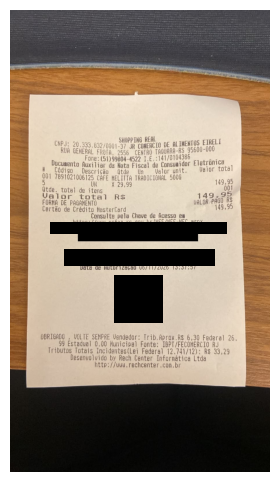

In [7]:
CAMINHO = enviados[0]
import matplotlib.pyplot as plt
plt.figure(figsize=(4, 6)); plt.imshow(Image.open(CAMINHO)); plt.axis("off"); plt.show()

## 3. A chamada multimodal

Repare em dois detalhes do prompt:
- ele pede um formato fixo para cada campo, o que facilita a validação;
- a instrução "use null se não tiver certeza" dá ao modelo uma saída honesta e reduz alucinações.

Um bom prompt de extração tem quatro partes: **a tarefa** (extrair), **os campos** com nomes exatos, **o formato** de cada um e **o que fazer na dúvida**. Primeiro vamos montar a mensagem e olhar o que vai ser enviado; depois, fazer a chamada.

In [8]:
PROMPT = (
    "Extraia do documento os campos emitente, data e valor_total. "
    "Responda apenas em JSON com essas três chaves. "
    "Use a data no formato DD/MM/AAAA e o valor com vírgula decimal, sem R$. "
    "Use null se não tiver certeza de algum campo."
)

# Monta a mensagem multimodal e mostra sua estrutura, com a imagem encurtada
mensagem = msg_com_imagem(PROMPT, CAMINHO)
visivel = json.loads(json.dumps(mensagem))
url = visivel[1]["image_url"]["url"]
visivel[1]["image_url"]["url"] = url[:45] + "... (cortado)"
print(json.dumps(visivel, indent=2, ensure_ascii=False))
print(f"A imagem viaja como {len(url) / 1024:.0f} KB de texto em base64")

[
  {
    "type": "text",
    "text": "Extraia do documento os campos emitente, data e valor_total. Responda apenas em JSON com essas três chaves. Use a data no formato DD/MM/AAAA e o valor com vírgula decimal, sem R$. Use null se não tiver certeza de algum campo."
  },
  {
    "type": "image_url",
    "image_url": {
      "url": "data:image/jpeg;base64,/9j/4AAQSkZJRgABAQAAAQ... (cortado)"
    }
  }
]
A imagem viaja como 136 KB de texto em base64


In [9]:
# Agora a chamada de verdade
campos, uso, prov = chamar_modelo(mensagem, json_mode=True)
print("Provedor que respondeu:", prov)
print(json.dumps(campos, indent=2, ensure_ascii=False))
print("Tokens de entrada:", uso.prompt_tokens, "| tokens de saída:", uso.completion_tokens)

Provedor que respondeu: groq
{
  "emitente": "JR COMERCIO DE ALIMENTOS EIRELI",
  "data": "06/11/2026",
  "valor_total": "149,95"
}
Tokens de entrada: 839 | tokens de saída: 54


**Para pensar** (não precisa escrever a resposta): algum campo veio `null`? Os formatos de data e de valor seguiram o pedido do prompt? Rode a célula da chamada de novo: a resposta vem do cache, e por quê?

## 4. Validação campo a campo

Digite abaixo os valores **corretos**, lidos por você no documento, e compare.

**Como a validação funciona**
- `GABARITO` guarda a verdade, digitada por você olhando o documento. Sem essa referência não há como medir; em projetos reais, ela vem de documentos já conferidos por pessoas.
- `normalizar(v)` deixa os dois lados no mesmo formato antes de comparar: tira espaços do começo e do fim (`strip`), passa para minúsculas (`lower`) e remove "R$" e espaços. Um valor `None` (o `null` do JSON) vira texto vazio.
- O laço compara campo a campo, conta os acertos (`True` vale 1 na soma) e calcula a acurácia.

In [10]:
GABARITO = {
    "emitente": "JR COMERCIO DE ALIMENTOS EIRELI",      # digite como está no cupom
    "data": "06/11/2026",          # ex.: 31/10/2026
    "valor_total": "149,95",   # ex.: 42,90
}


def normalizar(v):
    return str(v).strip().lower().replace("r$", "").replace(" ", "") if v is not None else ""


acertos = 0
print(f"{'campo':<12} {'extraído':<28} {'correto':<28} ok?")
for k, certo in GABARITO.items():
    ok = normalizar(campos.get(k)) == normalizar(certo)
    acertos += ok
    print(f"{k:<12} {str(campos.get(k)):<28} {certo:<28} {'sim' if ok else 'NÃO'}")
print(f"\nAcurácia por campo: {acertos}/{len(GABARITO)} = {acertos / len(GABARITO):.0%}")

campo        extraído                     correto                      ok?
emitente     JR COMERCIO DE ALIMENTOS EIRELI JR COMERCIO DE ALIMENTOS EIRELI sim
data         06/11/2026                   06/11/2026                   sim
valor_total  149,95                       149,95                       sim

Acurácia por campo: 3/3 = 100%


### Minha validação

Conferi o cupom e digitei no gabarito os valores reais: a razão social do emitente (JR COMERCIO DE ALIMENTOS EIRELI), a data de emissão (06/11/2026) e o valor total (R$ 149,95). O cupom também mostra o nome fantasia SHOPPING REAL na primeira linha, mas usei a razão social porque é ela que identifica o emitente da NFC-e. O modelo qwen/qwen3.8-27b, no Groq, acertou os três campos, com acurácia por campo de 3/3 = 100%, e nenhum veio null.

**Atenção à comparação:** formatos diferentes podem marcar como erro algo que está certo. Por isso o prompt fixou os formatos de data e valor. Definir o formato da saída é parte do design da aplicação.

**Para pensar** (não precisa escrever a resposta): algum campo foi marcado como erro só por formatação (por exemplo, "42.90" contra "42,90")? Que regra você acrescentaria em `normalizar` para corrigir isso, e que risco essa regra traria?

## 5. Quanto a imagem custa em tokens?

Enviamos a mesma imagem em três resoluções e comparamos os tokens de entrada com uma chamada só de texto. A diferença é o custo da imagem. O cache está desligado aqui (`usar_cache=False`) para que cada chamada seja realmente feita.

**O que esperar.** Os tokens da imagem acompanham o **número de patches**, que cresce com a **área**, e não com o lado. Dobrar o lado quadruplica os pixels:

| Lado maior | Pixels (imagem quadrada) | Em relação a 512 px |
| --- | --- | --- |
| 512 px | 262 mil | 1× |
| 1024 px | 1,05 milhão | 4× |
| 1600 px | 2,56 milhões | 9,8× |

Na prática, muitos provedores **redimensionam a imagem por conta própria** ou limitam o número de tokens por imagem. Se os tokens pararem de crescer acima de certa resolução, é isso que está acontecendo: enviar mais pixels gasta banda, mas não melhora a leitura.

Esta célula faz 4 chamadas seguidas. Se aparecer "limite atingido", é o limite por minuto do plano gratuito: a função espera e continua sozinha.

In [11]:
_, so_texto, _ = chamar_modelo(PROMPT, max_tokens=5, usar_cache=False)
print(f"{'só texto':<14} {so_texto.prompt_tokens:>6} tokens de entrada")
resultado = {}
for lado in [512, 1024, 1600]:
    campos_r, uso_r, _ = chamar_modelo(msg_com_imagem(PROMPT, CAMINHO, lado), json_mode=True, usar_cache=False)
    resultado[lado] = campos_r
    print(f"{f'imagem {lado}px':<14} {uso_r.prompt_tokens:>6} tokens de entrada | valor lido: {campos_r.get('valor_total')}")

só texto           69 tokens de entrada
imagem 512px      839 tokens de entrada | valor lido: 149,95
imagem 1024px     839 tokens de entrada | valor lido: 149.95
imagem 1600px     839 tokens de entrada | valor lido: 149,95


### Meus resultados de tokens

A chamada só de texto usou 69 tokens de entrada. As três resoluções usaram 839, ou seja, a imagem custou 770 tokens em 512, 1024 e 1600 px. Como o Groq contou o mesmo valor nas três, ele deve redimensionar a imagem por conta própria: mais pixels não aumentaram o custo nem melhoraram a leitura. O valor total saiu certo nas três chamadas, mas em 1024 px veio como 149.95, com ponto, fora do formato pedido no prompt. Com a normalização atual, esse campo contaria como erro, o que mostra que o formato precisa ser conferido mesmo quando o modelo lê o número certo. Para este cupom, 512 px bastam.

**Leitura:** com mais resolução, mais tokens, e a relação cresce com a área da imagem, como na conta de patches da aula. Cada provedor tem sua regra exata de contagem, por isso os números variam entre Groq, Gemini e OpenAI.

**Para pensar** (não precisa escrever a resposta): a versão de 512 pixels leu o valor corretamente? Se sim, você economizou tokens e ficou mais longe do limite por minuto, sem perder qualidade. Quantos tokens a imagem custou em cada resolução (tokens com imagem menos tokens só de texto)?

## 6. E o custo em dinheiro?

Nos planos gratuitos, o custo é zero dentro dos limites. Para projetar o custo de um produto real, consulte a página de preços do provedor e preencha os valores em dólares por **milhão** de tokens.

$$\text{custo} = \text{tokens de entrada} \times \frac{\text{preço de entrada}}{10^6} + \text{tokens de saída} \times \frac{\text{preço de saída}}{10^6}$$

**Exemplo com preços ilustrativos:** 1.200 tokens de entrada a US$ 0,15 por milhão e 40 de saída a US$ 0,60 por milhão dão US$ 0,00018 + US$ 0,000024 = **US$ 0,000204** por documento, ou cerca de **US$ 2** para 10 mil documentos. O preço da saída costuma ser maior, mas aqui a entrada domina, porque a imagem pesa muito mais que a resposta curta em JSON.

In [12]:
# Fonte dos preços: tabela de modelos do Groq (console.groq.com/docs/models) e página do modelo
# (console.groq.com/docs/model/qwen/qwen3.8-27b), consultadas em 11/11/2026 para qwen/qwen3.8-27b.
# Se a chamada tiver sido respondida por outro provedor, troque pelos preços dele.
PRECO_ENTRADA = 0.80   # US$ por 1 milhão de tokens de entrada
PRECO_SAIDA = 4.00     # US$ por 1 milhão de tokens de saída

custo = uso.prompt_tokens * PRECO_ENTRADA / 1e6 + uso.completion_tokens * PRECO_SAIDA / 1e6
print(f"Custo desta chamada: US$ {custo:.6f}")
print(f"Custo para 10 mil documentos por mês: US$ {custo * 10_000:.2f}")

Custo desta chamada: US$ 0.000887
Custo para 10 mil documentos por mês: US$ 8.87


Com os preços do qwen/qwen3.8-27b no Groq (US$ 0,80 por milhão de tokens de entrada e US$ 4,00 por milhão de saída), a extração deste cupom, com 839 tokens de entrada e 54 de saída, custaria US$ 0,000887, ou cerca de US$ 8,87 para 10 mil documentos por mês. A entrada, quase toda ocupada pela imagem, responde por cerca de três quartos do custo.

## 7. Quiz

Responda às 5 perguntas abaixo na célula de respostas, com a letra da alternativa certa (a, b, c ou d). Cada pergunta tem uma única resposta correta. Depois, rode a célula de conferência e salve o notebook para enviar.

**1. Por que a chave de API fica nos Secrets do Colab, e não no código?**

- **a)** Para a chave não aparecer no código, em prints ou no GitHub
- **b)** Para a chamada ficar mais rápida
- **c)** Porque o Python não aceita textos longos no código
- **d)** Para ativar o plano gratuito

**2. O que significa o erro 429?**

- **a)** A chave está errada
- **b)** A imagem é grande demais
- **c)** O limite de uso do plano foi atingido
- **d)** O modelo não existe

**3. Por que reduzir a resolução da imagem antes de enviar?**

- **a)** Porque o modelo só lê imagens de 512 pixels
- **b)** Porque menos pixels geram menos tokens: menor custo e mais distância do limite
- **c)** Porque o base64 só funciona com imagens pequenas
- **d)** Para melhorar as cores da foto

**4. Para que serve a instrução "use null se não tiver certeza" no prompt?**

- **a)** Para deixar o JSON menor
- **b)** Para a resposta chegar mais rápido
- **c)** Porque o modo JSON exige essa frase
- **d)** Para dar ao modelo uma saída honesta e reduzir valores inventados

**5. Em um cupom, o modelo acertou o emitente e a data, mas errou o valor total. Qual é a acurácia por campo?**

- **a)** 33%
- **b)** 50%
- **c)** 67%
- **d)** 100%

In [13]:
RESPOSTAS = {
    1: "a",   # a, b, c ou d
    2: "c",   # a, b, c ou d
    3: "b",   # a, b, c ou d
    4: "d",   # a, b, c ou d
    5: "c",   # a, b, c ou d
}

In [14]:
# Conferência: mostra seu nome e suas respostas e avisa o que falta (não mostra a nota)
faltando = [q for q, r in RESPOSTAS.items() if str(r).strip().lower() not in ("a", "b", "c", "d")]
print("Aluno:", ALUNO or "NOME NÃO PREENCHIDO: volte à célula de identificação, no início")
if MATRICULA:
    print("Matrícula:", MATRICULA)
print("Respostas:", {q: str(r).strip().lower() for q, r in RESPOSTAS.items()})
if faltando:
    print("Atenção, perguntas sem resposta válida:", faltando)
else:
    print("Quiz completo. Salve o notebook (Arquivo > Fazer download > .ipynb) e envie pelo portal.")

Aluno: Tales Rodrigo Ferreira Kerschner
Respostas: {1: 'a', 2: 'c', 3: 'b', 4: 'd', 5: 'c'}
Quiz completo. Salve o notebook (Arquivo > Fazer download > .ipynb) e envie pelo portal.


## Se algo der errado

| Mensagem | O que significa | O que fazer |
| --- | --- | --- |
| `Cadastre o segredo ...` | A chave não foi encontrada | Confira o nome do segredo e se o acesso do notebook está ativado |
| `401` ou `invalid api key` | A chave está errada ou foi apagada | Copie a chave de novo, sem espaços, ou crie outra no site do provedor |
| `limite atingido; nova tentativa` | Erro 429: limite por minuto | Aguarde; a função tenta de novo sozinha. Reduza a resolução da imagem |
| `model not found` | O nome do modelo mudou | Consulte os modelos com visão na documentação do provedor e atualize `PROVEDORES` |
| `Nenhum provedor respondeu` | Todos os limites ou chaves falharam | Espere alguns minutos ou cadastre a chave de outro provedor |

## Para entregar

- [ ] Nome preenchido na célula de identificação
- [ ] JSON gerado e provedor usado (seção 3)
- [ ] Validação campo a campo e acurácia (seção 4)
- [ ] Comparação de tokens entre resoluções (seção 5)
- [ ] Quiz respondido e conferido (seção 7)

Antes de baixar, use **Ambiente de execução > Reiniciar e executar tudo** e confira que nenhuma chave aparece no código ou nas saídas.